[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jeremydwong/bonelab_inverse_dynamics/blob/main/notebooks/p1_playground.ipynb)

# Inverse Dynamics Playground — notebook form

The notebook twin of the [interactive playground page]: the same ten steps as
`examples/quickstart.py`, but with every analysis choice as a variable you can
edit and re-run, an inspection plot after each step, and — at the end — the
**time-sweep sync check**: the sum-squared residual force computed at every
force↔mocap offset, plotted (not interactive; ~1 minute to run).

## How to run

```bash
uv run jupyter lab notebooks/p1_playground.ipynb
```

Edit the knobs in the config cell, then *Run All*. On Colab, run the
bootstrap cell and set `DATA_URL` first.

In [1]:
# Colab bootstrap — a no-op when running locally in the uv environment.
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "boneid @ git+https://github.com/jeremydwong/bonelab_inverse_dynamics"],
                   check=True)
os.makedirs("../reports", exist_ok=True)

## The knobs — edit these, then Run All

`LAG_MS` is the star: the force record is evaluated at `t − τ`. The two
systems are *assumed* synchronized — the true lag is unknowable from the
export — so this knob lets you feel what mis-sync does before the final
sweep quantifies it.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

MAT_PATH = "/Users/jeremy/Dropbox/Public/inverse-dynamics-test-data/p1_5StridesData.mat"
if not os.path.exists(MAT_PATH):
    for alt in ("p1_5StridesData.mat", "../data/p1_trial13_sample.mat"):
        if os.path.exists(alt):
            MAT_PATH = alt
            break
TRIAL_INDEX = 13

LAG_MS = 0.0                   # force <-> mocap time offset, try -50..50
CONTACT_THRESHOLD_N = 20.0     # vertical force marking ground contact
KINEMATIC_LOWPASS_HZ = 12.0    # segment-pose filter before differentiation
FORCE_LOWPASS_HZ = 0.0         # extra force filter (0 = anti-alias only)
BODY_MASS_KG = None            # None = estimate from full-stride mean GRF
TREADMILL_ORIGIN = np.zeros(3)
EDGE = 10                      # frames trimmed from every statistic (83 ms,
                               # covers the largest LAG_MS shift)

## Step 1 — mocap data
`load_v3d_trial` reads one trial slot: markers, hip landmarks, both time
bases. Inspect anything — here, the two heel markers' height, which already
shows the alternating gait.

trial 13: 637 frames at 120 Hz, 35 markers, analog 1200 Hz


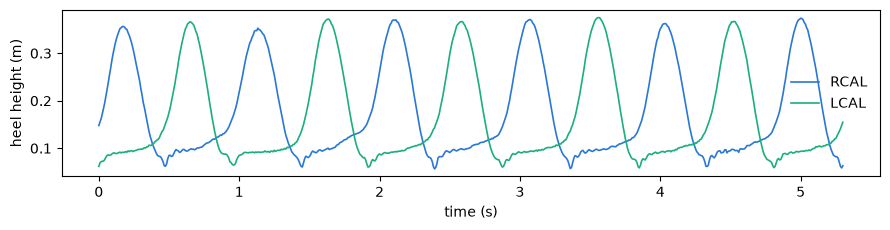

In [3]:
from boneid.io_v3d import load_v3d_trials

trials = load_v3d_trials(MAT_PATH)
trial = next((t for t in trials if t.index == TRIAL_INDEX), trials[0])
print(f"trial {trial.index}: {len(trial.t)} frames at {trial.rate:.0f} Hz, "
      f"{len(trial.markers)} markers, analog {trial.analog_rate:.0f} Hz")

plt.figure(figsize=(9, 2.4))
for name, c in (("RCAL", "#2a78d6"), ("LCAL", "#1baf7a")):
    plt.plot(trial.t, trial.markers[name][:, 2], color=c, lw=1.2, label=name)
plt.xlabel("time (s)"); plt.ylabel("heel height (m)"); plt.legend(frameon=False)
plt.tight_layout()

## Step 2 — force data, and the time-offset knob
The plate wrenches ride on the trial at the analog rate. This is where
`LAG_MS` enters: a helper that evaluates any ground wrench at `t − τ`
(a slide with edge-clamping — never a wrap — and `EDGE` trims more frames
than the largest shift, so no clamped sample reaches a statistic).

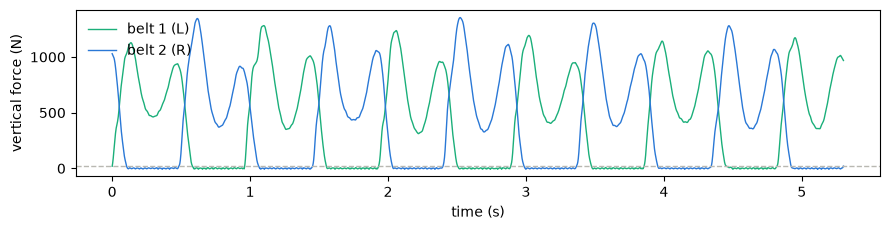

In [4]:
from dataclasses import replace

def shift_wrench_in_time(ground, lag_s):
    """Ground wrench evaluated at t - lag_s (slide + edge clamp)."""
    t = ground.t
    f = np.stack([np.interp(t - lag_s, t, ground.force[:, c]) for c in range(3)], axis=1)
    m = np.stack([np.interp(t - lag_s, t, ground.moment[:, c]) for c in range(3)], axis=1)
    return replace(ground, force=f, moment=m)

plt.figure(figsize=(9, 2.4))
for p, (lab, c) in enumerate((("belt 1 (L)", "#1baf7a"), ("belt 2 (R)", "#2a78d6"))):
    plt.plot(trial.t_analog, trial.force[:, p, 2], color=c, lw=1.0, label=lab)
plt.axhline(CONTACT_THRESHOLD_N, color="#b9b8b2", ls="--", lw=1)
plt.xlabel("time (s)"); plt.ylabel("vertical force (N)"); plt.legend(frameon=False)
plt.tight_layout()

## Step 3 — body mass
The full-stride mean of total vertical GRF equals body weight — that identity
needs an integer number of strides, so `estimate_body_mass` uses same-foot
onset-to-onset windows, accepts quiet standing (where the mean is body weight
regardless), and *raises* on anything else. `BODY_MASS_KG` overrides it while
keeping the marker-measured skeleton.

In [5]:
from boneid.io_v3d import estimate_body_mass

body_mass = BODY_MASS_KG if BODY_MASS_KG is not None else estimate_body_mass(
    trial, threshold_n=CONTACT_THRESHOLD_N)
print(f"body mass = {body_mass:.1f} kg "
      + ("(override)" if BODY_MASS_KG is not None else "(full-stride GRF mean)"))

body mass = 85.2 kg (full-stride GRF mean)


## Step 4 — analysis parameters
Every filter and threshold in one record; the knobs land here.

In [6]:
from boneid.core import AnalysisParams

params = AnalysisParams(contact_threshold_n=CONTACT_THRESHOLD_N,
                        lowpass_hz=KINEMATIC_LOWPASS_HZ,
                        force_lowpass_hz=FORCE_LOWPASS_HZ)
params

AnalysisParams(gravity=array([ 0.  ,  0.  , -9.81]), contact_threshold_n=20.0, lowpass_hz=12.0, force_lowpass_hz=0.0, filter_order=4, treadmill_speed=0.0, flag_crossover=False)

## Step 5 — the chains
Joint centres from marker pairs and landmarks, segment frames from anatomical
axes, de Leva segment parameters at the measured lengths — one call per leg
plus the upper body. The time offset is applied to both belts' wrenches
here.

In [7]:
from boneid.io_v3d import build_chain, build_upper_body

skel_r, kin_r, ground_r = build_chain(trial, side="r", point=TREADMILL_ORIGIN,
                                      threshold_n=CONTACT_THRESHOLD_N,
                                      body_mass=body_mass)
skel_l, kin_l, ground_l = build_chain(trial, side="l", point=TREADMILL_ORIGIN,
                                      threshold_n=CONTACT_THRESHOLD_N,
                                      body_mass=body_mass)
skel_u, kin_u = build_upper_body(trial, threshold_n=CONTACT_THRESHOLD_N,
                                 body_mass=body_mass)
ground_r = shift_wrench_in_time(ground_r, LAG_MS / 1000.0)
ground_l = shift_wrench_in_time(ground_l, LAG_MS / 1000.0)
for name, skel in (("right leg", skel_r), ("upper body", skel_u)):
    print(f"{name}: segments {skel.segment_names}")
    print(f"   masses {np.round(skel.mass, 2)} kg, lengths {np.round(skel.length, 3)} m")

right leg: segments ['foot', 'shank', 'thigh', 'pelvis']
   masses [ 1.17  3.69 12.06  9.51] kg, lengths [0.229 0.394 0.411 0.115] m
upper body: segments ['r_forearm_hand', 'r_upper_arm', 'l_forearm_hand', 'l_upper_arm', 'torso']
   masses [ 1.9   2.31  1.9   2.31 33.41] kg, lengths [0.295 0.349 0.282 0.344 0.447] m


## Step 6 — contact and crossover

double-support (crossover) frames: {'r': 133, 'l': 133}


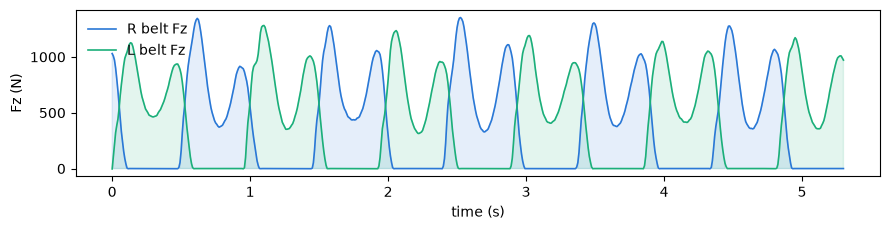

In [8]:
from boneid.core import detect_contact
from boneid.io_v3d import crossover_flags

contact = {s: detect_contact(g.force[:, 2], CONTACT_THRESHOLD_N)
           for s, g in (("r", ground_r), ("l", ground_l))}
cross = {s: crossover_flags(trial, s, CONTACT_THRESHOLD_N) for s in ("r", "l")}
plt.figure(figsize=(9, 2.4))
for s, c in (("r", "#2a78d6"), ("l", "#1baf7a")):
    g = ground_r if s == "r" else ground_l
    plt.plot(trial.t, g.force[:, 2], color=c, lw=1.2, label=f"{s.upper()} belt Fz")
    plt.fill_between(trial.t, 0, g.force[:, 2], where=contact[s][0], color=c, alpha=.12)
plt.xlabel("time (s)"); plt.ylabel("Fz (N)"); plt.legend(frameon=False)
plt.tight_layout()
print("double-support (crossover) frames:",
      {s: int(v.sum()) for s, v in cross.items()})

## Step 7 — whole-body inverse dynamics
Legs bottom-up, pelvis balanced with both hip reactions, arms into the torso,
torso balance → the residual.

In [9]:
from boneid.core import inverse_dynamics_whole_body

whole = inverse_dynamics_whole_body(skel_r, kin_r, ground_r,
                                    skel_l, kin_l, ground_l,
                                    skel_u, kin_u, params)
print("done:", whole.right.joint_torque.shape, "per-leg joint torques")

done: (637, 3, 3) per-leg joint torques


## Step 8 — the outputs
Sagittal torques over Visual3D's own export (grey — computed by them at zero
offset, so it is the fixed reference), and the residual force with its
numbers. Re-run with `LAG_MS = 30` and watch both degrade.

In [10]:
from boneid.io_v3d import reference_series
from boneid.report import v3d_ref_torque

e = slice(EDGE, -EDGE)
fig, axes = plt.subplots(2, 3, figsize=(9.5, 4.6), sharex=True)
rms = []
for row, side in enumerate("rl"):
    legs = whole.right if side == "r" else whole.left
    for j, name in enumerate(v3d_ref_torque(side)):
        ref = reference_series(trial, name)
        ax = axes[row, j]
        ax.plot(trial.t, ref[:, 0], color="#b9b8b2", lw=2.2)
        ax.plot(trial.t, legs.joint_torque[:, j, 0],
                color=["#2a78d6", "#eb6834", "#1baf7a"][j], lw=1.0)
        ax.set_title(f"{side.upper()} {['ankle','knee','hip'][j]}", fontsize=9)
        rms.append(float(np.sqrt(np.mean(
            (legs.joint_torque[e, j, 0] - ref[e, 0]) ** 2))))
fig.supylabel("torque, lab x (N m)"); fig.supxlabel("time (s)")
plt.tight_layout()
print(f"median torque RMS vs V3D: {np.median(rms):.2f} N m")

res = whole.residual_force
plt.figure(figsize=(9, 2.6))
for c, lab in enumerate("xyz"):
    plt.plot(trial.t, res[:, c], lw=1.0, label=f"F{lab}",
             color=["#2a78d6", "#eb6834", "#1baf7a"][c])
plt.xlabel("time (s)"); plt.ylabel("residual force (N)"); plt.legend(frameon=False, ncol=3)
plt.tight_layout()
print(f"mean |F_res| = {np.linalg.norm(res[e], axis=1).mean():.0f} N, "
      f"peak |F| = {np.abs(res[e]).max():.0f} N")

median torque RMS vs V3D: 3.41 N m
mean |F_res| = 102 N, peak |F| = 327 N


## Step 9 — the energy audit
d(KE+PE)/dt must equal the summed wrench powers; the imbalance is the
correctness instrument, independent of the recursion.

In [11]:
from boneid.core import energy_audit_whole_body

audit = energy_audit_whole_body(skel_r, kin_r, ground_r, skel_l, kin_l,
                                ground_l, skel_u, kin_u, whole, params)
imb = float(np.abs(audit.imbalance[e]).max())
pk = float(np.abs(audit.de_dt[e]).max())
plt.figure(figsize=(9, 2.4))
plt.plot(trial.t, audit.de_dt, color="#b9b8b2", lw=2.2, label="d(KE+PE)/dt")
plt.plot(trial.t, audit.power_total, color="#2a78d6", lw=1.0, label="summed wrench power")
plt.xlabel("time (s)"); plt.ylabel("power (W)"); plt.legend(frameon=False)
plt.tight_layout()
print(f"max imbalance {imb:.0f} W = {100 * imb / pk:.1f}% of peak dE/dt")

max imbalance 7 W = 0.9% of peak dE/dt


## Step 10 — the time-sweep sync check

> "If the other sources of experimental error are small, it is possible that
> residual forces can be helpful for identifying the presence or sensitivity
> of mis-synchronization" — Lemaire & Kuo 2024 (bioRxiv 600392), who report
> residuals growing ~1% body weight per ms in walking; see also Günther et
> al. 2005.

The sweep below re-runs the whole-body recursion at every offset τ from −50
to +50 ms and plots the sum of squared residual force (edge-trimmed, fixed
window, shared body mass — every guard from the audit). Takes about a
minute. What to look for: a parabola, shallow within ±5 ms (small lags are
not inferable), whose minimum sits near **−7 ms** rather than 0 — matching
the ~8 ms internal processing delay Lemaire & Kuo measured on the same
lab's Bertec treadmill that recorded this dataset.

In [12]:
# fresh unshifted wrenches so the sweep is independent of LAG_MS above
_, _, g_r0 = build_chain(trial, side="r", point=TREADMILL_ORIGIN,
                         threshold_n=CONTACT_THRESHOLD_N, body_mass=body_mass)
_, _, g_l0 = build_chain(trial, side="l", point=TREADMILL_ORIGIN,
                         threshold_n=CONTACT_THRESHOLD_N, body_mass=body_mass)
lags = np.arange(-50, 51, 5)
ssq = []
for lag in lags:
    w = inverse_dynamics_whole_body(
        skel_r, kin_r, shift_wrench_in_time(g_r0, lag / 1000.0),
        skel_l, kin_l, shift_wrench_in_time(g_l0, lag / 1000.0),
        skel_u, kin_u, params)
    ssq.append(float((w.residual_force[e] ** 2).sum()) / 1e6)
ssq = np.array(ssq)

plt.figure(figsize=(6.5, 3.2))
plt.plot(lags, ssq, color="#2a78d6", lw=1.6, marker="o", ms=3)
i0 = int(np.argmin(ssq))
plt.annotate(f"min {lags[i0]:+d} ms", (lags[i0], ssq[i0]),
             textcoords="offset points", xytext=(0, 12), ha="center")
plt.scatter([lags[i0]], [ssq[i0]], color="#52514e", zorder=5)
plt.xlabel("force ↔ mocap offset τ (ms)")
plt.ylabel("Σ|F_residual|² (10⁶ N²)")
plt.title("the time-sweep sync check", fontsize=11)
plt.tight_layout()
print(f"residual-minimizing offset: {lags[i0]:+d} ms; "
      f"value at 0 ms is {ssq[lags.tolist().index(0)] / ssq[i0]:.2f}x the minimum")

residual-minimizing offset: -5 ms; value at 0 ms is 1.17x the minimum
